In [1]:
!pip install opencv-python
!pip install tensorflow
!pip install lime scikit-image

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 5.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283834 sha256=de8bc026f3b788f5ef9155ff6c27a15dfd6b10855e152e094986ce8f54c72904
  Stored in directory: /root/.cache/pip/wheels/85/fa/a3/9c2d44c9f3cd77cf4e533b58900b2bf4487f2a17e8ec212a3d
Successfully built lime


In [2]:
import pandas as pd              # Data manipulation and analysis
import numpy as np               # Numerical computations and array handling
import matplotlib.pyplot as plt  # Basic plotting and visualization
import seaborn as sns            # Enhanced statistical visualizations
import os                        # Filesystem operations
import cv2                       # OpenCV for image processing
from PIL import Image            # Image handling and manipulation
from itertools import chain

In [3]:
from sklearn.utils.class_weight import compute_class_weight  # Balancing class weights
from sklearn.metrics import (                                # Model evaluation metrics
    confusion_matrix, classification_report, accuracy_score,
    precision_score, recall_score, f1_score
)
from sklearn.model_selection import train_test_split

In [4]:
from tensorflow.keras.models import load_model, Model, Sequential  # Model creation and loading
from tensorflow.keras import layers, regularizers, Model
from tensorflow.keras.optimizers import Adamax, SGD               # Optimization algorithms
from tensorflow.keras.regularizers import l2                      # Regularization for preventing overfitting
from tensorflow.keras.utils import to_categorical, plot_model     # Data preprocessing and model visualization
from tensorflow.keras.callbacks import (                          # Training callbacks
    EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
)
from tensorflow.keras.preprocessing.image import img_to_array

In [5]:
from tensorflow.keras.preprocessing import image_dataset_from_directory  # Dataset loading from directories
from tensorflow.keras.preprocessing.image import ImageDataGenerator     # Real-time data augmentation

In [6]:
from tensorflow.keras.applications import (                      # Classic pretrained CNN architectures
    VGG16, EfficientNetB0, InceptionV3, MobileNetV2, DenseNet121
)
from tensorflow.keras.applications.efficientnet import EfficientNetB0  # EfficientNet model

In [7]:
import warnings
warnings.filterwarnings('ignore')

In [8]:
plt.style.use('seaborn-v0_8-whitegrid')  # Clean, professional aesthetic
sns.set_palette("deep")  # Subtle, professional color scheme

In [9]:
H, W = 224, 224
IMG_SIZE = (H, W)                      # Standard input size for pretrained models
IMG_SHAPE = (H, W, 3)
BATCH_SIZE = 32                       # Number of samples per gradient update
EPOCHS = 30                          # Maximum training iterations
LEARNING_RATE = 0.0001                 # Initial learning rate for optimizers
CLASS_NAMES = ['NORMAL', 'PNEUMONIA']  # Example class labels pneumonia
CLASS_COUNT = len(CLASS_NAMES)

In [10]:
import os
import pandas as pd

# Define the base directory where your data is stored (adjust this path)
base_dir = "/content/drive/MyDrive/ColabNotebooks/Dulieu/chest_xray/chest_xray"  # e.g., "C:/pneumonia_project/data"

# List of dataset splits
splits = ["test", "train", "val"]
labels = ["NORMAL", "PNEUMONIA"]

# Initialize lists to store file paths and labels
file_paths = []
file_labels = []

# Loop through each split (train, valid, test)
for split in splits:
    split_dir = os.path.join(base_dir, split)
    # Loop through each label (normal, pneumonia)
    for label in labels:
        label_dir = os.path.join(split_dir, label)

        # Check if the directory exists
        if os.path.exists(label_dir):
            # Get all files in the label directory
            for file_name in os.listdir(label_dir):
                # Ensure it's a file (not a directory)
                if os.path.isfile(os.path.join(label_dir, file_name)):
                    # Add the full file path and corresponding label
                    file_paths.append(os.path.join(label_dir, file_name))
                    file_labels.append(label)

# Create a DataFrame with 'name' and 'label' columns
df = pd.DataFrame({
    "name": file_paths,
    "label": file_labels
})

# Optional: Save to a CSV file
df.to_csv("pneumonia_dataset.csv", index=False)
print("DataFrame saved as 'pneumonia_dataset.csv'")

DataFrame saved as 'pneumonia_dataset.csv'


In [11]:
df.head()

,name,label
0,/content/drive/MyDrive/ColabNotebooks/Dulieu/c...,NORMAL
1,/content/drive/MyDrive/ColabNotebooks/Dulieu/c...,NORMAL
2,/content/drive/MyDrive/ColabNotebooks/Dulieu/c...,NORMAL
3,/content/drive/MyDrive/ColabNotebooks/Dulieu/c...,NORMAL
4,/content/drive/MyDrive/ColabNotebooks/Dulieu/c...,NORMAL


In [12]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Assuming your DataFrame is already created (e.g., from the previous step)
# If not, load it from the CSV:
# df = pd.read_csv("pneumonia_dataset.csv")

# Shuffle the DataFrame
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

# First split: 70% train, 30% remaining
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,  # 30% for valid + test
    stratify=df["label"],  # Ensure label proportions are maintained
    random_state=42
)

# Second split: 20% valid, 10% test (from the original data)
# Since temp_df is 30%, we split it as 2/3 (20%) and 1/3 (10%) of original
valid_df, test_df = train_test_split(
    temp_df,
    test_size=0.333,  # 10/30 = 1/3 for test
    stratify=temp_df["label"],
    random_state=42
)

# Verify the sizes
print(f"Train set: {len(train_df)} samples ({len(train_df)/len(df)*100:.1f}%)")
print(f"Validation set: {len(valid_df)} samples ({len(valid_df)/len(df)*100:.1f}%)")
print(f"Test set: {len(test_df)} samples ({len(test_df)/len(df)*100:.1f}%)")
print(f"Total: {len(train_df) + len(valid_df) + len(test_df)} samples")


# Optional: Save the splits to CSV files
train_df.to_csv("train_split.csv", index=False)
valid_df.to_csv("valid_split.csv", index=False)
test_df.to_csv("test_split.csv", index=False)
print("\nSplits saved as 'train_split.csv', 'valid_split.csv', and 'test_split.csv'")

Train set: 4102 samples (70.0%)
Validation set: 1172 samples (20.0%)
Test set: 586 samples (10.0%)
Total: 5860 samples

Splits saved as 'train_split.csv', 'valid_split.csv', and 'test_split.csv'


In [13]:
%matplotlib inline


In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

def plot_data_distribution(df, train_df, valid_df, test_df):
    """Vẽ biểu đồ phân phối dữ liệu đẹp hơn"""
    plt.figure(figsize=(18, 12), facecolor='white')

    # 1. Pie Chart: Dataset Split
    plt.subplot(2, 2, 1)
    sizes = [len(train_df), len(valid_df), len(test_df)]
    labels = ['Training Set', 'Validation Set', 'Test Set']
    colors = ['#66b3ff', '#99ff99', '#ffcc99']
    explode = (0.05, 0.05, 0.05)

    patches, texts, autotexts = plt.pie(sizes, labels=labels, colors=colors,
                                       autopct=lambda pct: f'{pct:.1f}%\n({int(pct/100.*sum(sizes))})',
                                       startangle=90, explode=explode,
                                       textprops={'fontsize': 12},
                                       wedgeprops={'edgecolor': 'white', 'linewidth': 1, 'alpha': 0.7})

    plt.setp(autotexts, size=12, weight="bold")
    plt.title('Dataset Split', fontsize=14, fontweight='bold', pad=20)

    # 2. Bar Plot: Overall Label Distribution
    plt.subplot(2, 2, 2)
    ax2 = sns.countplot(x="label", data=df, palette="Set2", edgecolor='black', linewidth=0.5)

    for p in ax2.patches:
        height = p.get_height()
        ax2.text(p.get_x() + p.get_width()/2., height + 3,
                f'{int(height)}\n({height/len(df)*100:.1f}%)',
                ha='center', va='bottom', fontsize=11)

    plt.title("Overall Label Distribution", fontsize=14, fontweight='bold', pad=10)
    plt.xlabel("Class", fontsize=12)
    plt.ylabel("Count", fontsize=12)
    plt.grid(axis='y', linestyle='--', alpha=0.7)

    # 3. Pie Chart: Label Proportion
    plt.subplot(2, 2, 3)
    value_counts = df["label"].value_counts(normalize=True)
    value_counts.plot(kind="pie", autopct="%1.1f%%",
                     colors=['#ff9999','#66b3ff'],
                     textprops={'fontsize': 12},
                     wedgeprops={'edgecolor': 'white', 'linewidth': 1, 'alpha': 0.7})
    plt.title("Label Proportion", fontsize=14, fontweight='bold', pad=10)
    plt.ylabel("")

    # 4. Grouped Bar Plot: Label Distribution by Split
    plt.subplot(2, 2, 4)
    combined_df = pd.concat([
        train_df.assign(split="Train"),
        valid_df.assign(split="Validation"),
        test_df.assign(split="Test")
    ])

    ax = sns.countplot(x="label", hue="split", data=combined_df,
                      palette="pastel", edgecolor='black', linewidth=0.5)

    for p in ax.patches:
        height = p.get_height()
        if height > 0:
            ax.text(p.get_x() + p.get_width()/2., height + 2,
                   f'{int(height)}', ha='center', va='bottom', fontsize=10)

    plt.title("Label Distribution by Split", fontsize=14, fontweight='bold', pad=10)
    plt.xlabel("Class", fontsize=12)
    plt.ylabel("Count", fontsize=12)
    plt.legend(title="Dataset Split", title_fontsize=12, fontsize=10,
              bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(axis='y', linestyle='--', alpha=0.7)

    # Adjust layout
    plt.tight_layout(pad=3.0)
    plt.suptitle("Dataset and Label Distribution Analysis", fontsize=16, fontweight='bold', y=1.02)

    plt.show()

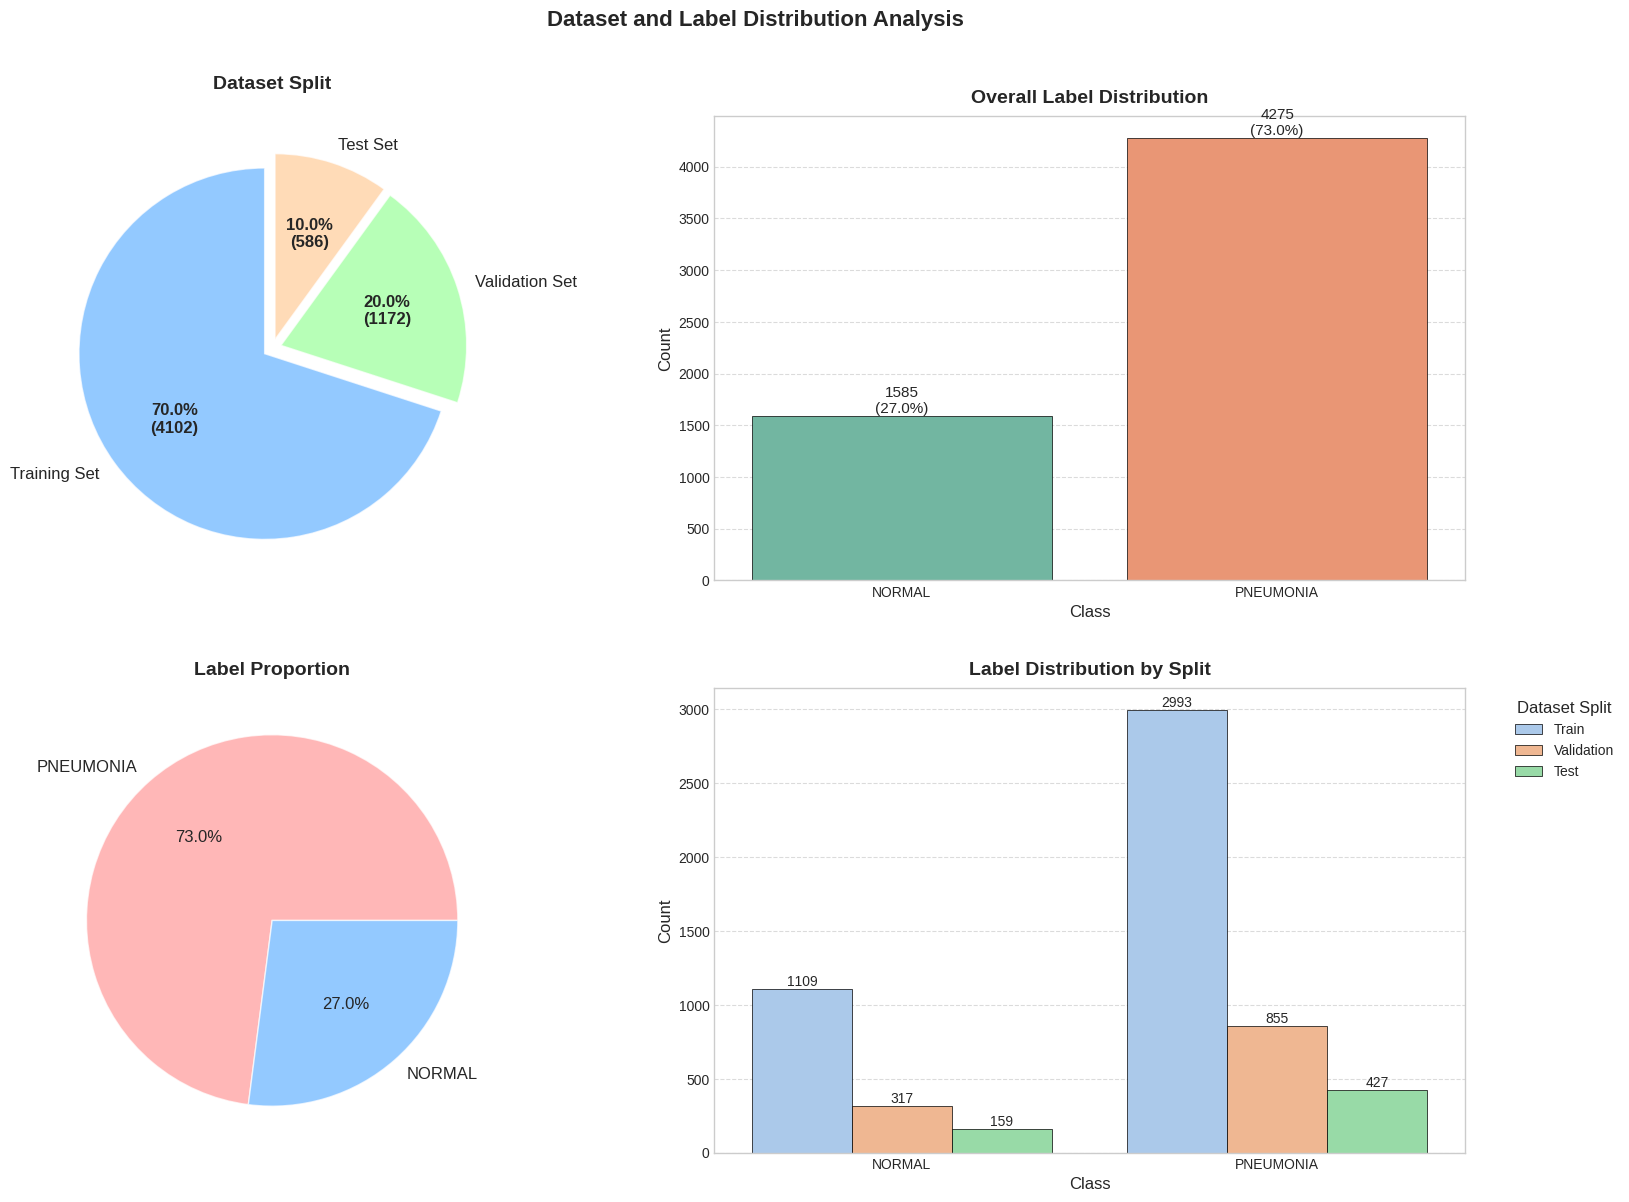

In [15]:
plot_data_distribution(df, train_df, valid_df, test_df)


In [16]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.efficientnet import preprocess_input

# Training generator với augmentation + preprocessing
tr_gen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True
)

# Validation/Test generator chỉ preprocessing
ts_gen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

train_gen = tr_gen.flow_from_dataframe(
    train_df, x_col='name', y_col='label',
    target_size=IMG_SIZE, class_mode='categorical',
    color_mode='rgb', shuffle=True, batch_size=BATCH_SIZE
)
valid_gen = ts_gen.flow_from_dataframe(
    valid_df, x_col='name', y_col='label',
    target_size=IMG_SIZE, class_mode='categorical',
    color_mode='rgb', shuffle=True, batch_size=BATCH_SIZE
)
test_gen = ts_gen.flow_from_dataframe(
    test_df, x_col='name', y_col='label',
    target_size=IMG_SIZE, class_mode='categorical',
    color_mode='rgb', shuffle=False, batch_size=BATCH_SIZE
)


Found 4100 validated image filenames belonging to 2 classes.
Found 1171 validated image filenames belonging to 2 classes.
Found 585 validated image filenames belonging to 2 classes.


In [17]:
# Get a single sample
sample_row = df[df["label"] == label].iloc[0]
img_path = sample_row["name"]

# Before generator: Load raw image
raw_img = Image.open(img_path)
if raw_img.mode != 'RGB':
    raw_img = raw_img.convert('RGB')
raw_img = raw_img.resize(IMG_SIZE, Image.Resampling.LANCZOS)  # Match generator size
raw_array = np.array(raw_img)
print(f"Before Generator (Raw Pixels, Shape: {raw_array.shape}):")
print(raw_array[0, :5, :])  # Print first row, first 5 pixels, all channels

Before Generator (Raw Pixels, Shape: (224, 224, 3)):
[[0 0 0]
 [0 0 0]
 [0 0 0]
 [2 2 2]
 [5 5 5]]


In [18]:
image_batch, label_batch = next(train_gen)

# Print pixel values after generator
print(f"After Generator (Processed Pixels, Shape: {image_batch.shape}):")
print(image_batch[0, 0, :5])  # First image, first 5 rows, all columns, all channels

After Generator (Processed Pixels, Shape: (32, 224, 224, 3)):
[[ 47.434845  47.434845  47.434845]
 [ 32.5275    32.5275    32.5275  ]
 [ 31.04535   31.04535   31.04535 ]
 [211.33     211.33     211.33    ]
 [ 81.550285  81.550285  81.550285]]


In [19]:
def plot_sample_images(df, label, num_samples=3, fixed_size=(224, 224)):
    # Filter by label
    label_df = df[df["label"] == label]

    if len(label_df) == 0:
        print(f"No images found for label '{label}'")
        return

    # Sample images
    samples = label_df.sample(min(num_samples, len(label_df)))

    # Set up figure with dark background
    plt.figure(figsize=(15, 5), facecolor='white')

    # Plot each image
    for i, (idx, row) in enumerate(samples.iterrows()):
        img = Image.open(row["name"])
        if img.mode != 'RGB':
            img = img.convert('RGB')
        img = img.resize(fixed_size, Image.Resampling.LANCZOS)

        plt.subplot(1, num_samples, i + 1)
        plt.imshow(img)
        plt.title(f"{label} #{i + 1}\nSize: {img.size}", fontsize=12)
        plt.axis("off")

    plt.suptitle(f"Sample {label} Images", fontsize=16, fontweight='bold', y=1.05)
    plt.tight_layout()
    plt.show()


Normal Samples:


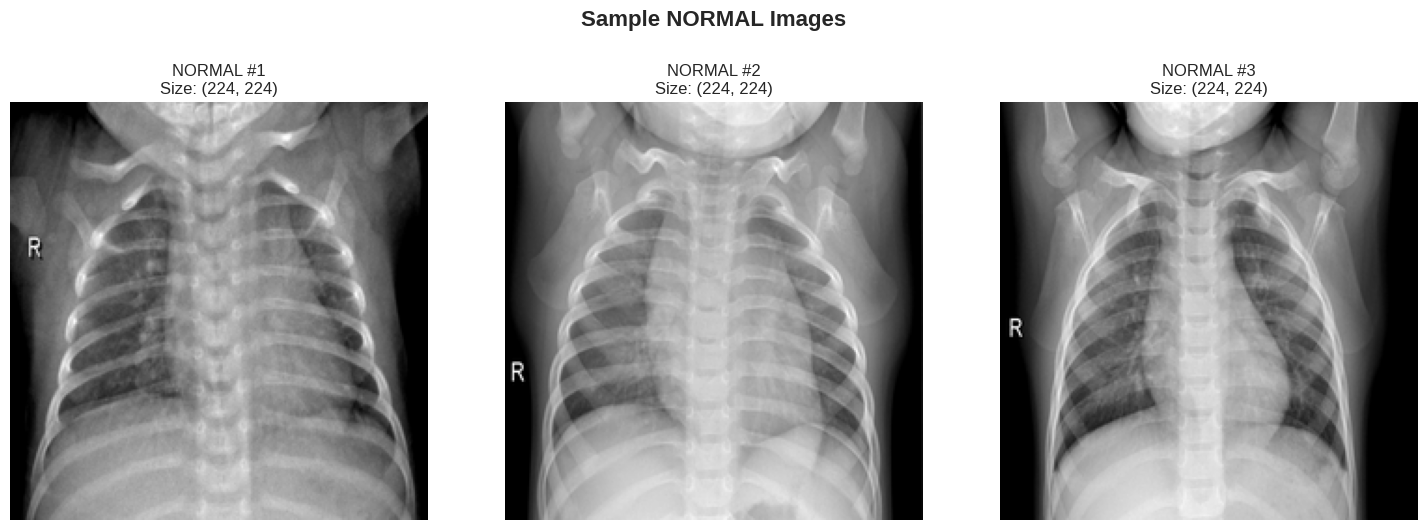


Pneumonia Samples:


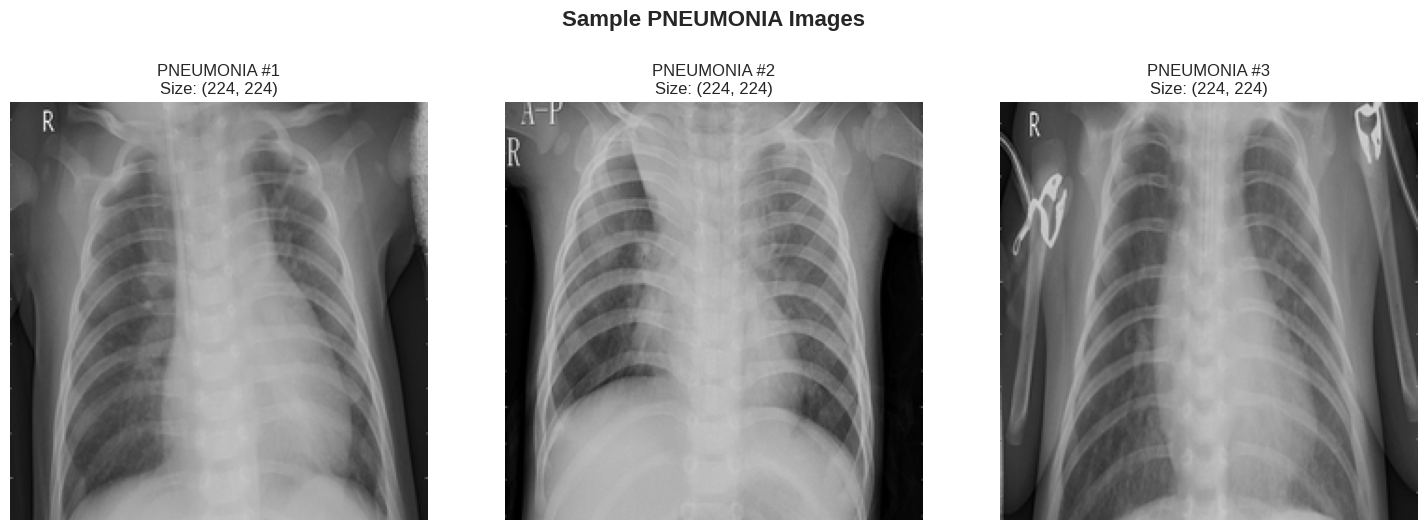

In [20]:
print("\nNormal Samples:")
plot_sample_images(train_df, "NORMAL")

print("\nPneumonia Samples:")
plot_sample_images(train_df, "PNEUMONIA")

In [21]:
# Define callbacks
callbacks = [
    ModelCheckpoint(filepath='/kaggle/working/best_model_V2.keras', monitor='val_accuracy',
                    save_best_only=True, verbose=1,mode='max'),

]

In [22]:

classes = list(train_gen.class_indices.keys())
class_indices = train_gen.class_indices


y_numeric = train_df['label'].map(class_indices)


class_weights = compute_class_weight(class_weight='balanced', classes=np.array(range(len(classes))), y=y_numeric)
class_weight_dict_mapped = dict(zip(class_indices.values(), class_weights))
class_weight_dict_mapped[0] *= 1.5  # Increase by 20%

In [23]:
def plot_training_history(history, figsize=(20, 8)):
    tr_acc = history.history['accuracy']
    tr_loss = history.history['loss']
    val_acc = history.history['val_accuracy']
    val_loss = history.history['val_loss']

    index_loss = np.argmin(val_loss)
    val_lowest = val_loss[index_loss]
    index_acc = np.argmax(val_acc)
    acc_highest = val_acc[index_acc]

    Epochs = [i+1 for i in range(len(tr_acc))]

    # Tạo figure với background màu trắng
    plt.figure(figsize=figsize, facecolor='white')

    # Subplot 1: Training and Validation Loss
    plt.subplot(1, 2, 1)
    plt.plot(Epochs, tr_loss, 'r', label='Training loss', linewidth=2)
    plt.plot(Epochs, val_loss, 'b', label='Validation loss', linewidth=2)
    plt.scatter(index_loss+1, val_lowest, s=150, c='blue', label=f'Best epoch: {index_loss+1}\nVal loss: {val_lowest:.4f}')

    # Thêm grid và styling
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.title('Training and Validation Loss', fontsize=14, fontweight='bold', pad=20)
    plt.xlabel('Epochs', fontsize=12)
    plt.ylabel('Loss', fontsize=12)
    plt.legend(framealpha=1, shadow=True, borderpad=1)

    # Subplot 2: Training and Validation Accuracy
    plt.subplot(1, 2, 2)
    plt.plot(Epochs, tr_acc, 'r', label='Training accuracy', linewidth=2)
    plt.plot(Epochs, val_acc, 'b', label='Validation accuracy', linewidth=2)
    plt.scatter(index_acc+1, acc_highest, s=150, c='blue',
                label=f'Best epoch: {index_acc+1}\nVal acc: {acc_highest:.4f}')

    # Thêm grid và styling
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.title('Training and Validation Accuracy', fontsize=14, fontweight='bold', pad=20)
    plt.xlabel('Epochs', fontsize=12)
    plt.ylabel('Accuracy', fontsize=12)
    plt.legend(framealpha=1, shadow=True, borderpad=1)

    # Điều chỉnh layout
    plt.tight_layout()

    # Thêm title chung
    plt.suptitle('Model Training History', fontsize=16, fontweight='bold', y=1.02)

    plt.show()

In [24]:
def evaluate_model(valid_gen, model):
    y_true = []
    y_pred = []


    for images, labels in valid_gen:
        preds = model.predict(images, verbose=0)  # Suppress extra output
        batch_y_pred = np.argmax(preds, axis=1)  # Convert probabilities to class labels
        batch_y_true = np.argmax(labels, axis=1)  # Convert one-hot encoding to class labels
        y_true.extend(batch_y_true)
        y_pred.extend(batch_y_pred)

        if len(y_true) >= valid_gen.samples:  # Stop when all data is processed
            break

    # Convert lists to numpy arrays
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    # Compute classification metrics
    acc = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average="weighted")
    recall = recall_score(y_true, y_pred, average="weighted")
    f1 = f1_score(y_true, y_pred, average="weighted")

    # Get class names from gen
    class_names = list(valid_gen.class_indices.keys())

    # Print classification report
    print("📊 Classification Report:\n")
    print(classification_report(y_true, y_pred, target_names=class_names))

    print(f"✅ Overall Accuracy: {acc*100:.4f}%")
    print(f"✅ Weighted Precision: {precision:.4f}")
    print(f"✅ Weighted Recall: {recall:.4f}")
    print(f"✅ Weighted F1-score: {f1:.4f}")

    # Compute Confusion Matrix
    cf_matrix = confusion_matrix(y_true, y_pred)

    # Plot Confusion Matrix
    group_names = ['True Neg','False Pos','False Neg','True Pos']
    group_counts = ['{0:0.0f}'.format(value) for value in
                    cf_matrix.flatten()]
    group_percentages = ['{0:.2%}'.format(value) for value in
                         cf_matrix.flatten()/np.sum(cf_matrix)]
    labels = [f'{v1}\n{v2}\n{v3}' for v1, v2, v3 in
              zip(group_names,group_counts,group_percentages)]
    labels = np.asarray(labels).reshape(2,2)
    sns.heatmap(cf_matrix, annot=labels, fmt='', cmap='Blues')  # Hide color bar with cbar=False

    return acc, precision, recall, f1

In [25]:
import tensorflow as tf
from tensorflow.keras import layers, regularizers, Model
from tensorflow.keras.utils import plot_model

def build_custom_model(
    base_model_class,
    img_shape,
    class_count,
    freeze_percentage=0.8,
    weights="imagenet",
    pooling="max",
    learning_rate=0.0001,
    plot_file="model_plot.png"
):
    """
    Build and compile a custom model using any pre-trained base from Keras Applications.

    Args:
        base_model_class: Keras Applications model class (e.g., tf.keras.applications.EfficientNetB0).
        img_shape: Tuple of input image shape (height, width, channels).
        class_count: Number of output classes.
        freeze_percentage: Fraction of base model layers to freeze (0 to 1, default 0.8).
        weights: Pre-trained weights to use (default "imagenet").
        pooling: Pooling method for base model (e.g., 'avg', 'max', None).
        learning_rate: Learning rate for optimizer (default 0.00001).
        plot_file: File path to save model plot (default "model_plot.png").

    Returns:
        Compiled Keras Model.
    """
    # Define input tensor
    inputs = tf.keras.Input(shape=img_shape)

    # Create pre-trained base model
    base_model = base_model_class(
        include_top=False,
        weights=weights,
        input_shape=img_shape,
        pooling=pooling
    )

    # Freeze a percentage of layers
    total_layers = len(base_model.layers)
    num_freeze = int(total_layers * freeze_percentage)
    for layer in base_model.layers[:num_freeze]:
        layer.trainable = False
    for layer in base_model.layers[num_freeze:]:
        layer.trainable = True

    # Pass input through base model
    x = base_model(inputs)

    # Add custom layers
    x = layers.BatchNormalization(axis=-1, momentum=0.99, epsilon=0.001)(x)
    x = layers.Dense(256, kernel_regularizer=regularizers.l2(0.01),
                     activity_regularizer=regularizers.l1(0.003),
                     bias_regularizer=regularizers.l1(0.003), activation='relu')(x)
    x = layers.Dropout(rate=0.3, seed=123)(x)
    x = layers.Dense(class_count, activation='softmax')(x)

    # Create and compile the model
    model = Model(inputs=inputs, outputs=x)
    model.compile(
        optimizer=tf.keras.optimizers.Adamax(learning_rate=learning_rate),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    # Display summary and save plot
    model.summary()
    plot_model(
        model,
        to_file=plot_file,
        show_shapes=True
    )
    print(f"Model plot saved as '{plot_file}'")

    return model

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 1280)           │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           514 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,383,141 (16.72 MB)

 Trainable params: 331,010 (1.26 MB)

 Non-trainable params: 4,052,131 (15.46 MB)

Model plot saved as 'model_EfficientNetB0_plot.png'
Epoch 1/30
129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 19s/step - accuracy: 0.7975 - loss: 12.7536 
Epoch 1: val_accuracy improved from -inf to 0.83860, saving model to /kaggle/working/best_model_V2.keras
129/129 ━━━━━━━━━━━━━━━━━━━━ 3125s 24s/step - accuracy: 0.7978 - loss: 12.7311 - val_accuracy: 0.8386 - val_loss: 4.8378
Epoch 2/30
129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8224 - loss: 4.4072
Epoch 2: val_accuracy did not improve from 0.83860
129/129 ━━━━━━━━━━━━━━━━━━━━ 490s 4s/step - accuracy: 0.8224 - loss: 4.4040 - val_accuracy: 0.7891 - val_loss: 3.3934
Epoch 3/30
129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8141 - loss: 3.2641
Epoch 3: val_accuracy did not improve from 0.83860
129/129 ━━━━━━━━━━━━━━━━━━━━ 460s 4s/step - accuracy: 0.8141 - loss: 3.2628 - val_accuracy: 0.8147 - val_loss: 2.8430
Epoch 4/30
129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8565 - loss: 2.6961
Epoch 4: val_accuracy improved from 0.838

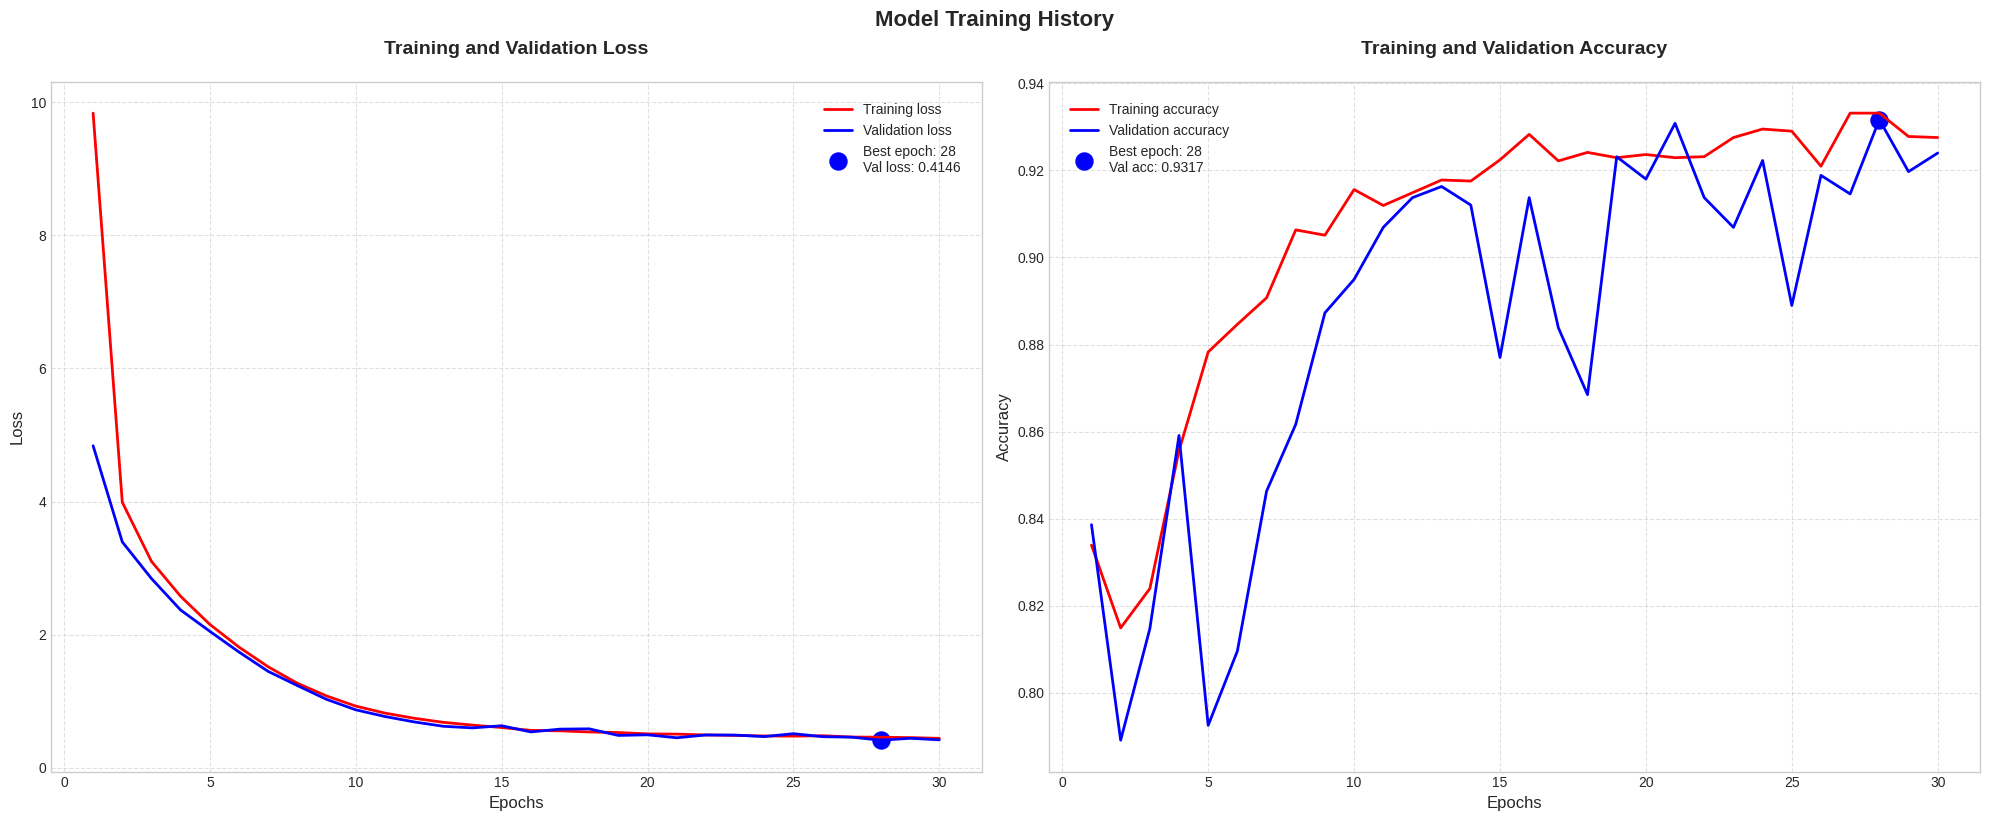

📊 Classification Report:

              precision    recall  f1-score   support

      NORMAL       0.80      0.96      0.87       316
   PNEUMONIA       0.98      0.91      0.95       855

    accuracy                           0.92      1171
   macro avg       0.89      0.93      0.91      1171
weighted avg       0.93      0.92      0.93      1171

✅ Overall Accuracy: 92.3997%
✅ Weighted Precision: 0.9334
✅ Weighted Recall: 0.9240
✅ Weighted F1-score: 0.9259


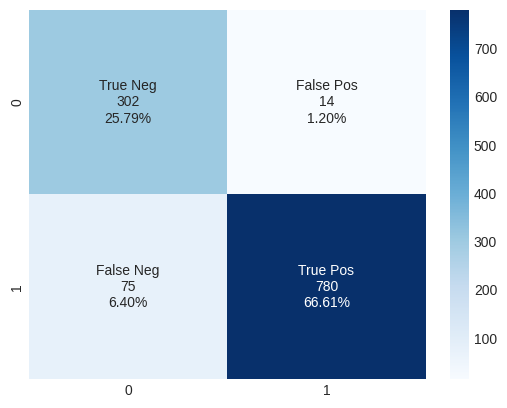

In [ ]:
model_EfficientNetB0 = build_custom_model(
    EfficientNetB0,
    IMG_SHAPE,
    CLASS_COUNT,
    freeze_percentage=1,
    weights="imagenet",
    pooling="max",
    learning_rate=0.001,
    plot_file="model_EfficientNetB0_plot.png"
)
history_EfficientNetB0= model_EfficientNetB0.fit(
    train_gen,
    validation_data=valid_gen,
    epochs=EPOCHS,
    verbose=1,
    class_weight=class_weight_dict_mapped,  # class weights
    callbacks=callbacks,


)
plot_training_history(history_EfficientNetB0, figsize=(20, 8))

# Save model
model_EfficientNetB0.save('/content/drive/MyDrive/ColabNotebooks/EfficientNetB0.keras')
model_EfficientNetB0.save('/content/drive/MyDrive/ColabNotebooks/EfficientNetB0.h5')

#Evaluate model
EfficientNetB0_acc,EfficientNetB0_precision,EfficientNetB0_recall,EfficientNetB0_f1=evaluate_model(valid_gen,model_EfficientNetB0 )

In [26]:
from tensorflow.keras.models import load_model
model = load_model('/content/drive/MyDrive/ColabNotebooks/EfficientNetB0.h5')


In [ ]:
# Define callbacks
callbacks = [

    ModelCheckpoint(filepath='/kaggle/working/Enhanced_model_V2.keras', monitor='val_accuracy',
                    save_best_only=True, verbose=1,mode='max'),
    ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=4, min_lr=1e-6, verbose=1)
]

In [ ]:
train_gen = tr_gen.flow_from_dataframe(
    train_df, x_col='name', y_col='label', target_size=IMG_SIZE,
    class_mode='categorical', color_mode='grayscale', shuffle=True, batch_size=BATCH_SIZE
)
valid_gen = ts_gen.flow_from_dataframe(
    valid_df, x_col='name', y_col='label', target_size=IMG_SIZE,
    class_mode='categorical', color_mode='grayscale', shuffle=True, batch_size=BATCH_SIZE
)
test_gen = ts_gen.flow_from_dataframe(
    test_df, x_col='name', y_col='label', target_size=IMG_SIZE,
    class_mode='categorical', color_mode='grayscale', shuffle=False, batch_size=BATCH_SIZE
)

Found 4100 validated image filenames belonging to 2 classes.
Found 1171 validated image filenames belonging to 2 classes.
Found 585 validated image filenames belonging to 2 classes.


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 1280)           │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │           514 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,383,141 (16.72 MB)

 Trainable params: 4,338,558 (16.55 MB)

 Non-trainable params: 44,583 (174.16 KB)

Model plot saved as 'model_plot.png'
Epoch 1/100
119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 627ms/step - accuracy: 0.5716 - loss: 16.6018
Epoch 1: val_accuracy improved from -inf to 0.81270, saving model to /kaggle/working/Enhanced_model_V2.keras
119/119 ━━━━━━━━━━━━━━━━━━━━ 172s 824ms/step - accuracy: 0.5724 - loss: 16.5905 - val_accuracy: 0.8127 - val_loss: 11.3777 - learning_rate: 1.0000e-04
Epoch 2/100
119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 316ms/step - accuracy: 0.8476 - loss: 10.1831
Epoch 2: val_accuracy improved from 0.81270 to 0.91042, saving model to /kaggle/working/Enhanced_model_V2.keras
119/119 ━━━━━━━━━━━━━━━━━━━━ 50s 424ms/step - accuracy: 0.8478 - loss: 10.1724 - val_accuracy: 0.9104 - val_loss: 7.1175 - learning_rate: 1.0000e-04
Epoch 3/100
119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 317ms/step - accuracy: 0.9148 - loss: 6.6247
Epoch 3: val_accuracy improved from 0.91042 to 0.92915, saving model to /kaggle/working/Enhanced_model_V2.keras
119/119 ━━━━━━━━━━━━━━━━━━━━ 50s 420ms/step - accuracy: 0.914

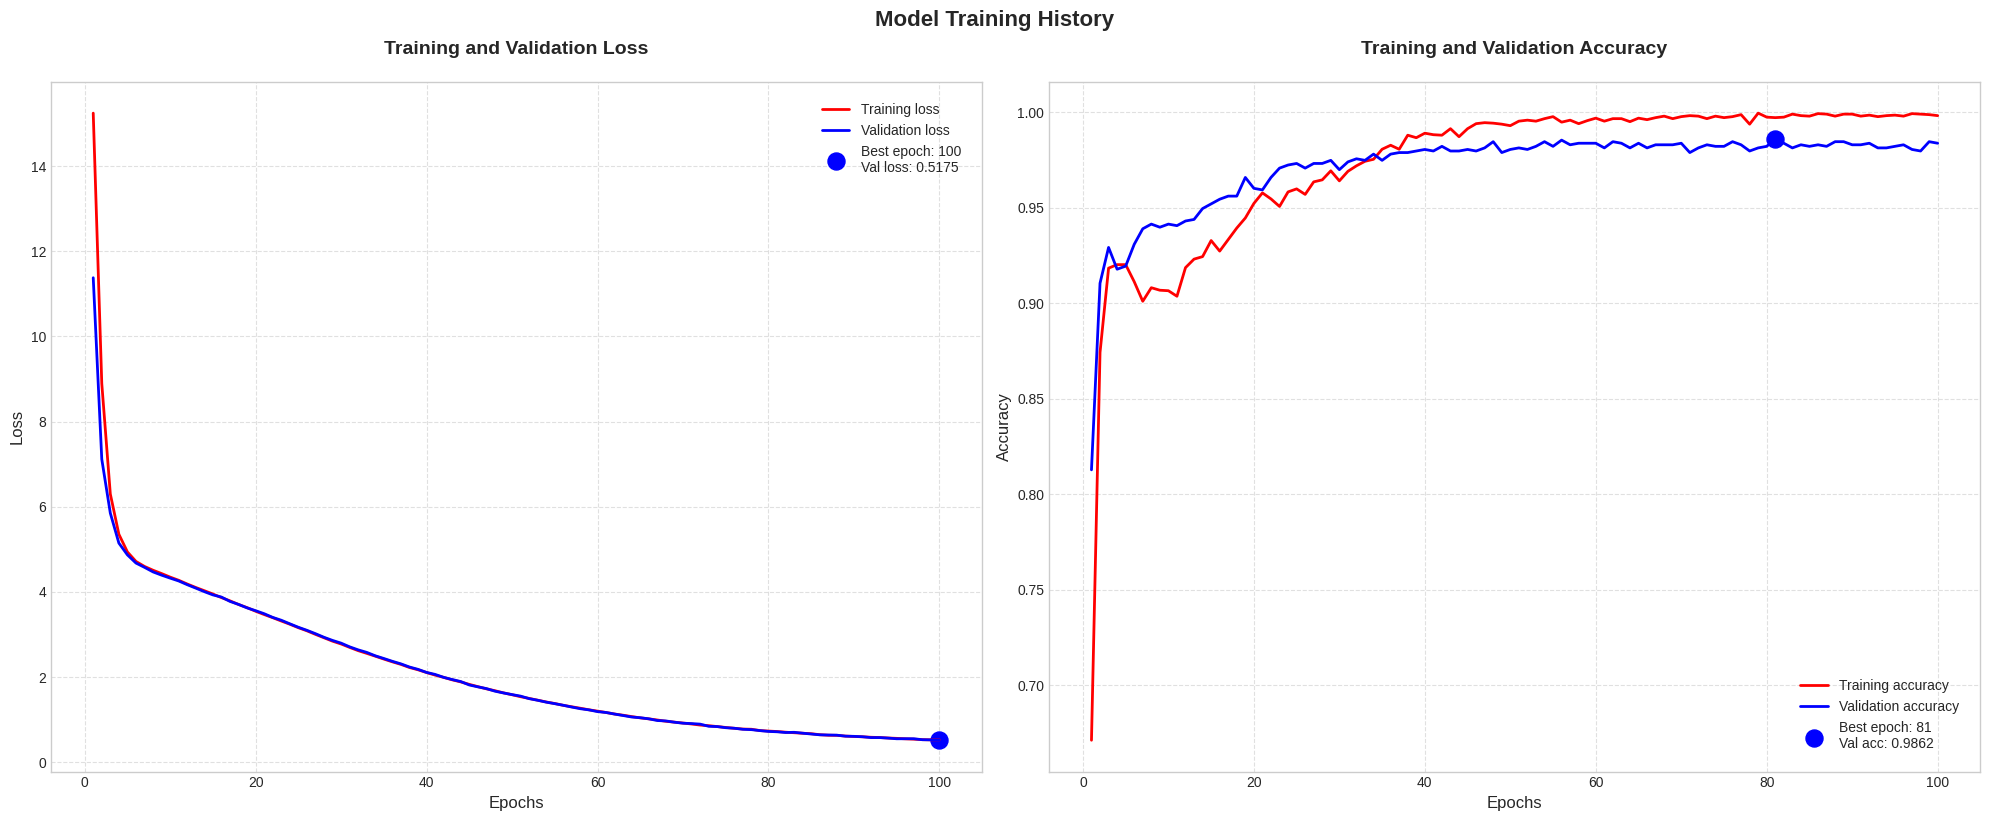

In [ ]:
model= build_custom_model(
    EfficientNetB0,
    IMG_SHAPE,
    CLASS_COUNT,
    freeze_percentage=0,
    weights="imagenet",
    pooling="max",
    learning_rate=0.0001,
    plot_file="model_plot.png"
)
# Fit with GPU (Kaggle handles GPU automatically)
history = model.fit(
    train_gen,
    validation_data=valid_gen,
    epochs=100,
    verbose=1,
    class_weight= class_weight_dict_mapped,
    callbacks=callbacks
)

# Evaluate on test set
test_loss, test_accuracy = model.evaluate(test_gen, verbose=1)
print(f"\nTest Accuracy: {test_accuracy:.4f}")
print(f"Test Loss: {test_loss:.4f}")
plot_training_history(history)

In [ ]:
# Lưu mô hình hoàn chỉnh
model.save('/content/drive/MyDrive/ColabNotebooks/EfficientNetB0_full_model.keras')
model.save('/content/drive/MyDrive/ColabNotebooks/EfficientNetB0_full_model.h5')

In [ ]:
from tensorflow.keras.models import load_model
model = load_model('/content/drive/MyDrive/ColabNotebooks/EfficientNetB0_full_model.h5')

In [ ]:
ts_length = len(test_df)
test_batch_size = max(sorted([ts_length // n for n in range(1, ts_length + 1) if ts_length%n == 0 and ts_length/n <= 80]))
test_steps = ts_length // test_batch_size

train_score = model.evaluate(train_gen, steps= test_steps, verbose= 1)
valid_score = model.evaluate(valid_gen, steps= test_steps, verbose= 1)
test_score = model.evaluate(test_gen, steps= test_steps, verbose= 1)

print("Train Loss: ", train_score[0])
print("Train Accuracy: ", train_score[1])
print('-' * 20)
print("Validation Loss: ", valid_score[0])
print("Validation Accuracy: ", valid_score[1])
print('-' * 20)
print("Test Loss: ", test_score[0])
print("Test Accuracy: ", test_score[1])

In [ ]:
save_path = "/content/drive/MyDrive/evaluation_results.txt"

with open(save_path, "w") as f:
    f.write(f"Train Loss: {train_score[0]:.4f}, Train Accuracy: {train_score[1]:.4f}\n")
    f.write(f"Validation Loss: {valid_score[0]:.4f}, Validation Accuracy: {valid_score[1]:.4f}\n")
    f.write(f"Test Loss: {test_score[0]:.4f}, Test Accuracy: {test_score[1]:.4f}\n")

print(f"Đã lưu kết quả vào {save_path}")


Đã lưu kết quả vào /content/drive/MyDrive/evaluation_results.txt


In [27]:
import matplotlib.pyplot as plt
import cv2
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.efficientnet import preprocess_input
import numpy as np

def predict_and_display_from_path(img_path, model, class_names):
    # Load ảnh
    img = image.load_img(img_path, target_size=(224, 224))
    img_array = image.img_to_array(img)
    img_array_preprocessed = preprocess_input(np.expand_dims(img_array.copy(), axis=0))

    # Dự đoán
    preds = model.predict(img_array_preprocessed)
    pred_class_index = np.argmax(preds[0])
    confidence = 100 * np.max(preds[0])
    predicted_label = class_names[pred_class_index]

    # Hiển thị
    plt.figure(figsize=(6, 6))
    plt.imshow(np.uint8(img_array))
    plt.axis('off')
    plt.title(
        f"Predicted: {predicted_label.upper()}\nConfidence: {confidence:.1f}%",
        fontsize=14,
        color='green' if predicted_label.lower() == "normal" else 'red',
        weight='bold'
    )
    plt.tight_layout()
    plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


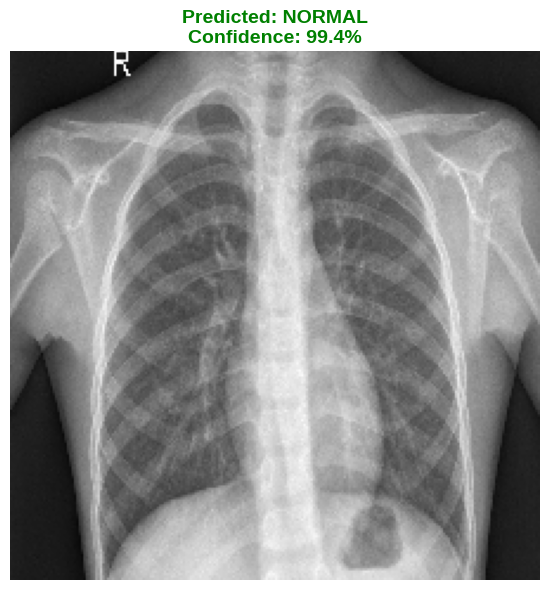

In [ ]:
from tensorflow.keras.models import load_model
model = load_model('/content/drive/MyDrive/EfficientNetB0.h5')
class_names = ['Normal', 'Pneumonia']

# Dự đoán từ đường dẫn ảnh
predict_and_display_from_path('/content/drive/MyDrive/ColabNotebooks/Dulieu/chest_xray/chest_xray/test/NORMAL/IM-0001-0001.jpeg', model, class_names)


In [ ]:
import requests
from PIL import Image
from io import BytesIO

def predict_and_display_from_url(img_url, model, class_names):
    # Tải ảnh từ URL
    response = requests.get(img_url)
    if response.status_code != 200:
        raise Exception("Không thể tải ảnh từ URL")

    img = Image.open(BytesIO(response.content)).convert('RGB')
    img_resized = img.resize((224, 224))
    img_array = image.img_to_array(img_resized)
    img_array_preprocessed = preprocess_input(np.expand_dims(img_array.copy(), axis=0))

    # Dự đoán
    preds = model.predict(img_array_preprocessed)
    pred_class_index = np.argmax(preds[0])
    confidence = 100 * np.max(preds[0])
    predicted_label = class_names[pred_class_index]

    # Hiển thị
    plt.figure(figsize=(6, 6))
    plt.imshow(img)
    plt.axis('off')
    plt.title(
        f"Predicted: {predicted_label.upper()}\nConfidence: {confidence:.1f}%",
        fontsize=14,
        color='green' if predicted_label.lower() == "normal" else 'red',
        weight='bold'
    )
    plt.tight_layout()
    plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


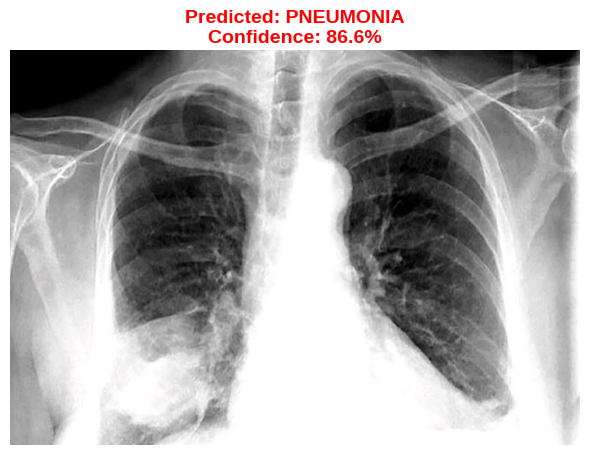

In [ ]:
from tensorflow.keras.models import load_model
model = load_model('/content/drive/MyDrive/EfficientNetB0.h5')
class_names = ['Normal', 'Pneumonia']
predict_and_display_from_url('https://www.bvduckhang.com/wp-content/uploads/2022/03/chan-doan-viem-phoi-cong-dong.jpg', model, class_names)

In [30]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from lime import lime_image
from skimage.segmentation import mark_boundaries

def explain_pneumonia_from_path(image_path, model, class_names):
    # 1. Mở và resize ảnh
    img = Image.open(image_path).convert('RGB')
    img = img.resize((224, 224))
    img_array = np.array(img, dtype=np.float32) / 255.0
    img_batch = np.expand_dims(img_array, axis=0)

    # 2. Dự đoán
    preds = model.predict(img_batch)
    if preds.shape[-1] == 1:
        prob = preds[0,0]
        predicted_class = int(prob >= 0.5)
    else:
        predicted_class = np.argmax(preds, axis=1)[0]
    print(f"Dự đoán: {class_names[predicted_class]} (score: {preds.flatten()})")

    # 3. Giải thích với LIME
    explainer = lime_image.LimeImageExplainer()
    explanation = explainer.explain_instance(
        image=img_array.astype('double'),
        classifier_fn=lambda x: model.predict(x),
        top_labels=1,
        hide_color=0,
        num_samples=1000
    )

    # 4. Lấy mask chỉ các vùng positive
    temp, mask = explanation.get_image_and_mask(
        label=predicted_class,
        positive_only=True,
        hide_rest=True,   # Chỉ giữ region positive
        num_features=5
    )

    # 5. Vẽ overlay LIME lên ảnh gốc
    lime_img = mark_boundaries(img_array, mask)

    # 6. Hiển thị
    plt.figure(figsize=(6,6))
    plt.imshow(lime_img)
    plt.title(f"Giải thích LIME → {class_names[predicted_class]}")
    plt.axis('off')
    plt.show()



1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 176ms/step
Dự đoán: Pneumonia (score: [0.3092578 0.6907422])


  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 926ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 839ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 552ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 498ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 538ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 520ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 560ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 533ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 514ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 902ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 832ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 707ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 497ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 532ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 510ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 528ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 509ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 489ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 487ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 504ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 533ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 482ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 566ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 532

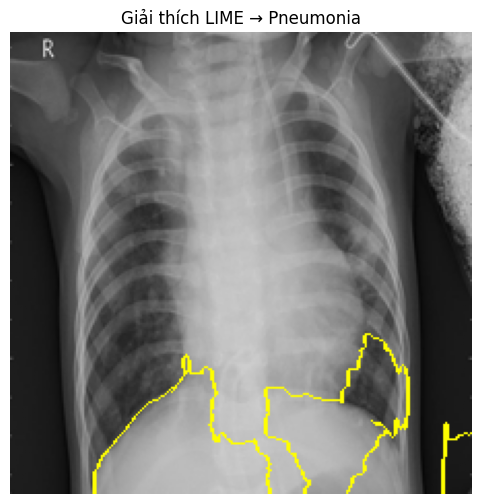

In [80]:
class_names = ['Normal','Pneumonia']
explain_pneumonia_from_path(
    '/content/drive/MyDrive/ColabNotebooks/Dulieu/chest_xray/chest_xray/test/PNEUMONIA/person103_bacteria_489.jpeg',
    model,
    class_names
)


In [17]:
import requests
from PIL import Image
from io import BytesIO


In [18]:
from PIL import Image
import requests
from io import BytesIO

def explain_pneumonia(image_url, model, class_names):
    # 1. Tải ảnh từ URL
    response = requests.get(image_url)
    if response.status_code != 200:
        raise Exception("Không thể tải ảnh từ URL")

    img = Image.open(BytesIO(response.content)).convert('RGB')  # Đảm bảo chuyển sang RGB
    img = img.resize((224, 224))

    # 2. Tiền xử lý ảnh
    img_array = np.array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    # 3. Dự đoán
    pred = model.predict(img_array)
    predicted_class = np.argmax(pred)

    print("Dự đoán:", class_names[predicted_class])

    # 4. Gọi LIME
    from lime import lime_image
    explainer = lime_image.LimeImageExplainer()
    explanation = explainer.explain_instance(
        np.array(img),
        model.predict,
        top_labels=1,
        hide_color=0,
        num_samples=1000
    )

    from skimage.segmentation import mark_boundaries
    temp, mask = explanation.get_image_and_mask(
        label=predicted_class,
        positive_only=True,
        hide_rest=False
    )

    plt.imshow(mark_boundaries(temp / 255.0, mask))
    plt.title(f"Giải thích LIME - {class_names[predicted_class]}")
    plt.axis('off')
    plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
Dự đoán: Pneumonia


  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 805ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 658ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 628ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 610ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 659ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 621ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 569ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 636ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 602ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 909ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 994ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 562ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 679ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 704ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 640ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 685ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 647ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 672ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 597ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 557ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 579ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 646ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 666ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 964

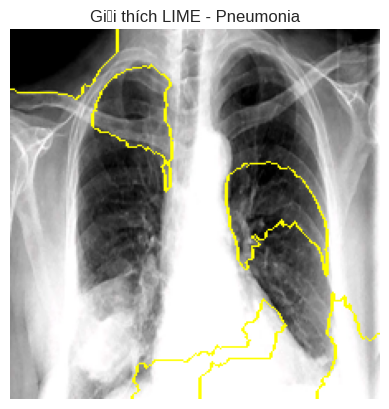

In [ ]:
model = load_model('/content/drive/MyDrive/EfficientNetB0.h5')
explain_pneumonia('https://www.bvduckhang.com/wp-content/uploads/2022/03/chan-doan-viem-phoi-cong-dong.jpg', model, ['Normal', 'Pneumonia'])

In [50]:
last_conv_layer = model.get_layer("efficientnetb0").get_layer("top_conv")


In [51]:
# Lấy mô hình EfficientNetB0 từ model gốc
effnet = model.get_layer("efficientnetb0")

# Lấy lớp convolution cuối cùng của EfficientNetB0
last_conv_layer = effnet.get_layer("top_conv")


1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
Dự đoán: Pneumonia (score: 68.84%)


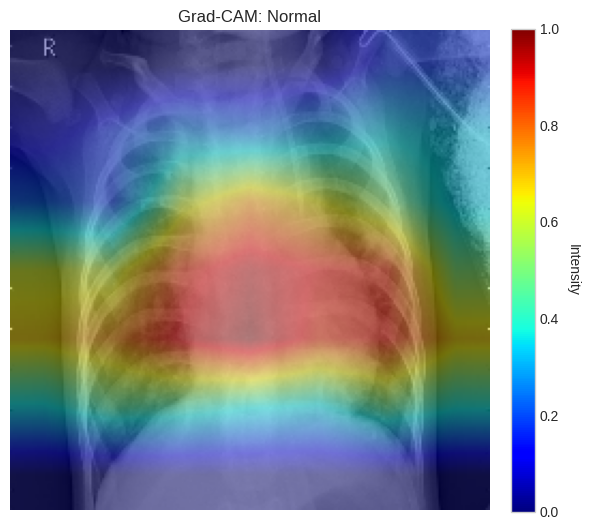

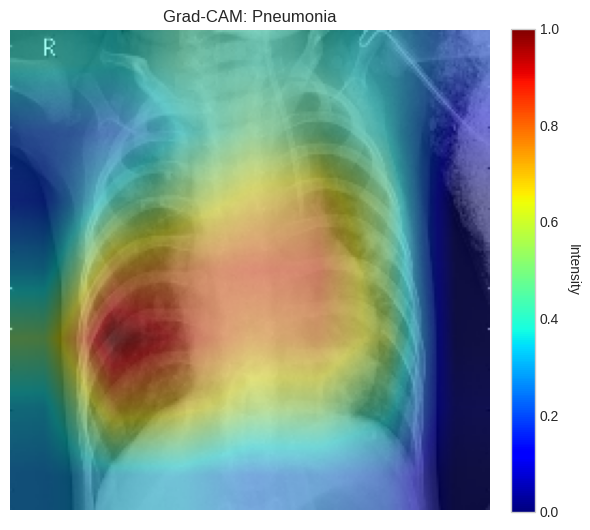

In [17]:
import tensorflow as tf
import numpy as np
import cv2
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.cm import ScalarMappable
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.efficientnet import preprocess_input

# ========== 1. Load model ==========
# Giả sử bạn đã load model ngoài, ví dụ:
model = tf.keras.models.load_model('/content/drive/MyDrive/EfficientNetB0_full_model.h5')

# ========== 2. Hàm load + tiền xử lý ảnh ==========
def get_img_array(img_path, size=(224, 224)):
    img = image.load_img(img_path, target_size=size)
    arr = image.img_to_array(img)
    arr = np.expand_dims(arr, axis=0)
    return preprocess_input(arr)

# ========== 3. Tạo heatmap Grad-CAM ==========
def make_gradcam_heatmap(img_array, model, pred_index=None):
    # Truy xuất EfficientNetB0 từ model tổng và lấy layer cuối cùng
    effnet = model.get_layer("efficientnetb0")
    last_conv = effnet.get_layer("top_conv")
    grad_model = tf.keras.models.Model(
        inputs=effnet.input,
        outputs=[last_conv.output, effnet.output]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        if pred_index is None:
            pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0,1,2))
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()

# ========== 4. Hiển thị ảnh + colorbar ==========
def display_gradcam(img_path, model, class_names):
    # 4.1 Load và dự đoán
    img_array = get_img_array(img_path)
    preds = model.predict(img_array)
    pred_class = np.argmax(preds[0])
    print(f"Dự đoán: {class_names[pred_class]} (score: {100*np.max(preds):.2f}%)")

    # 4.2 Đọc ảnh gốc, chuyển sang RGB và resize
    orig = cv2.imread(img_path)
    orig = cv2.cvtColor(orig, cv2.COLOR_BGR2RGB)
    orig = cv2.resize(orig, (224,224))

    # 4.3 Vẽ cho từng lớp
    for i, cls in enumerate(class_names):
        # Tạo heatmap
        heatmap = make_gradcam_heatmap(img_array, model, pred_index=i)
        hm_resized = cv2.resize(heatmap, (224,224))

        # Chuyển heatmap thành BGR rồi RGB để overlay
        hm_uint8 = np.uint8(255 * hm_resized)
        hm_color = cv2.applyColorMap(hm_uint8, cv2.COLORMAP_JET)
        hm_rgb   = cv2.cvtColor(hm_color, cv2.COLOR_BGR2RGB)

        # Overlay lên ảnh gốc
        superimposed = cv2.addWeighted(orig, 0.6, hm_rgb, 0.4, 0)

        # Chuẩn bị ScalarMappable cho colorbar
        norm = mcolors.Normalize(vmin=0, vmax=1)
        sm   = ScalarMappable(norm=norm, cmap='jet')
        sm.set_array([])

        # Vẽ ảnh + colorbar
        fig, ax = plt.subplots(figsize=(6,6))
        ax.imshow(superimposed)
        ax.axis('off')
        ax.set_title(f"Grad-CAM: {cls}")

        # Vẽ thanh màu bên cạnh
        cbar = fig.colorbar(sm, ax=ax, fraction=0.046, pad=0.04)
        cbar.set_label('Intensity', rotation=270, labelpad=15)

        plt.tight_layout()
        plt.show()

# ========== 5. Demo ==========
if __name__ == "__main__":
    # Thay path và class_names cho phù hợp
    img_path = "/content/drive/MyDrive/ColabNotebooks/Dulieu/chest_xray/chest_xray/test/PNEUMONIA/person103_bacteria_489.jpeg"
    class_names = ["Normal", "Pneumonia"]
    display_gradcam(img_path, model, class_names)
